In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import torch
import xgboost as xgb

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, RepeatedStratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier, VotingClassifier, StackingClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, make_scorer
from sklearn.preprocessing import FunctionTransformer

from config import N_REPEATS, N_SPLITS, SEED
from dnn import TorchDNNClassifier, train_dnn
from features import CATEGORICAL_FEATURES, NUMERIC_FEATURES, make_feature_engineer
from model import make_preprocessor
from validation import evaluate_model

sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
group_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
regular_cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED);

# Titanic Survival Prediction

This project compares several classification models using a reusable preprocessing pipeline

Accuracy is the main metric, while precision, recall and F1 are used for additional evaluation

In [2]:
raw_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

df = raw_df.copy()

print("Train shape:", raw_df.shape)
print("Test shape:", test_df.shape)

raw_df.head(10)

Train shape: (891, 12)
Test shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [5]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [6]:
missing_values = pd.DataFrame({"Missing count": df.isna().sum(),
                               "Missing percent": df.isna().mean().mul(100).round(2)})

missing_values = missing_values[missing_values["Missing count"] > 0]
missing_values.sort_values("Missing percent", ascending=False)

,Missing count,Missing percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


## Missing values

Age is missing for 177 passengers, cabin information for 687 passengers, and embarkation port for 2 passengers

Passenger titles and class are used to estimate age. Cabin information is reduced to deck, while remaining missing values are handled inside the preprocessing pipeline

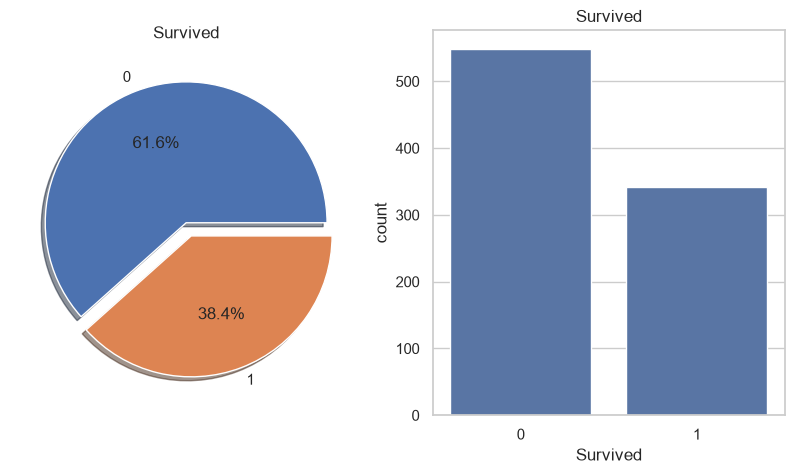

In [7]:
f,ax=plt.subplots(1,2,figsize=(10,5))
df["Survived"].value_counts().plot.pie(explode=[0,0.1],autopct="%1.1f%%",ax=ax[0],shadow=True)

ax[0].set_title("Survived")
ax[0].set_ylabel("")
sns.countplot(x="Survived", data=df, ax=ax[1])
ax[1].set_title("Survived")
plt.show()

## Target distribution

About 38% of passengers survived and 62% did not

The moderate class imbalance is handled with stratified validation splits

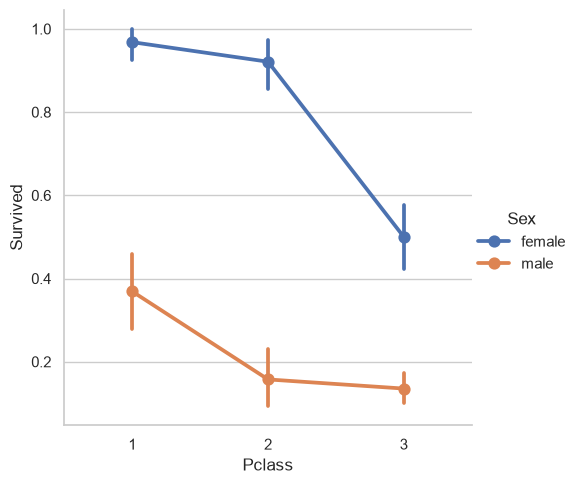

In [8]:
sns.catplot(data=df, x="Pclass", y="Survived", hue="Sex", kind="point")
plt.show()

## Sex and passenger class

Women survived more often than men: 74% versus 19%

Survival fell from 63% in first class to 47% in second class and 24% in third class. Sex and passenger class are useful predictors

In [9]:
# Extract passenger title from Name, for example "Mr", "Mrs" or "Miss"
df["Title"] = df["Name"].str.extract(r"([A-Za-z]+)\.", expand=False)

In [10]:
TITLE_MAPPING = {"Mlle": "Miss",
                "Ms": "Miss",
                "Mme": "Mrs",
                "Dr": "Other",
                "Major": "Other",
                "Col": "Other",
                "Capt": "Other",
                "Rev": "Other",
                "Don": "Other",
                "Sir": "Other",
                "Jonkheer": "Other",
                "Lady": "Other",
                "Countess": "Other",
                "Dona": "Other"}

df["Title"] = (df["Title"].replace(TITLE_MAPPING).fillna("Other"))

In [11]:
df["Title"].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Other      23
Name: count, dtype: int64

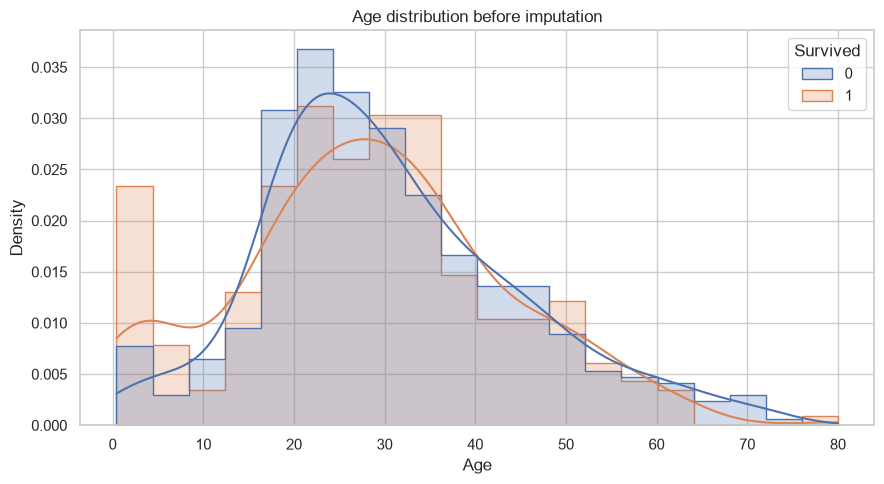

In [12]:
age_data = df.dropna(subset=["Age"])

plt.figure(figsize=(9, 5))
sns.histplot(data=age_data, x="Age", hue="Survived", bins=20, stat="density", common_norm=False, element="step", kde=True)

plt.xlabel("Age")
plt.ylabel("Density")
plt.title("Age distribution before imputation")
plt.tight_layout()
plt.show()

In [13]:
age_by_title_class = df.groupby(["Title", "Pclass"])["Age"].transform("median")
age_by_title = df.groupby("Title")["Age"].transform("median")
df["Age"] = (df["Age"].fillna(age_by_title_class).fillna(age_by_title).fillna(df["Age"].median()))

print("Missing Age:",df["Age"].isna().sum())

Missing Age: 0


## Age

Passengers younger than 16 survived more often than adults: 59% versus 38%

Titles and passenger class are used to estimate missing ages inside the pipeline

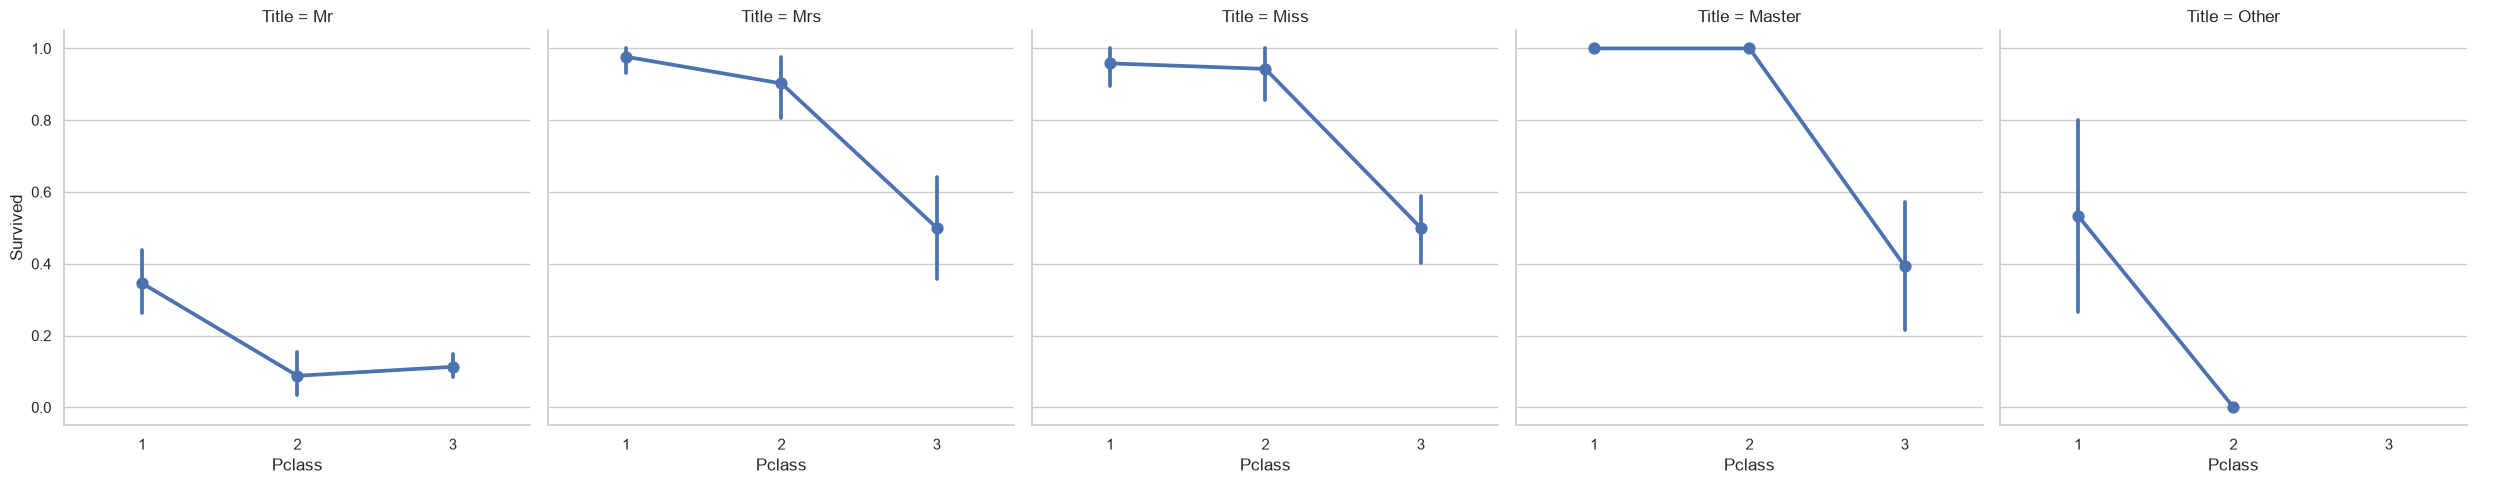

In [14]:
sns.catplot(data=df, x="Pclass", y="Survived", col="Title", kind="point")
plt.show()

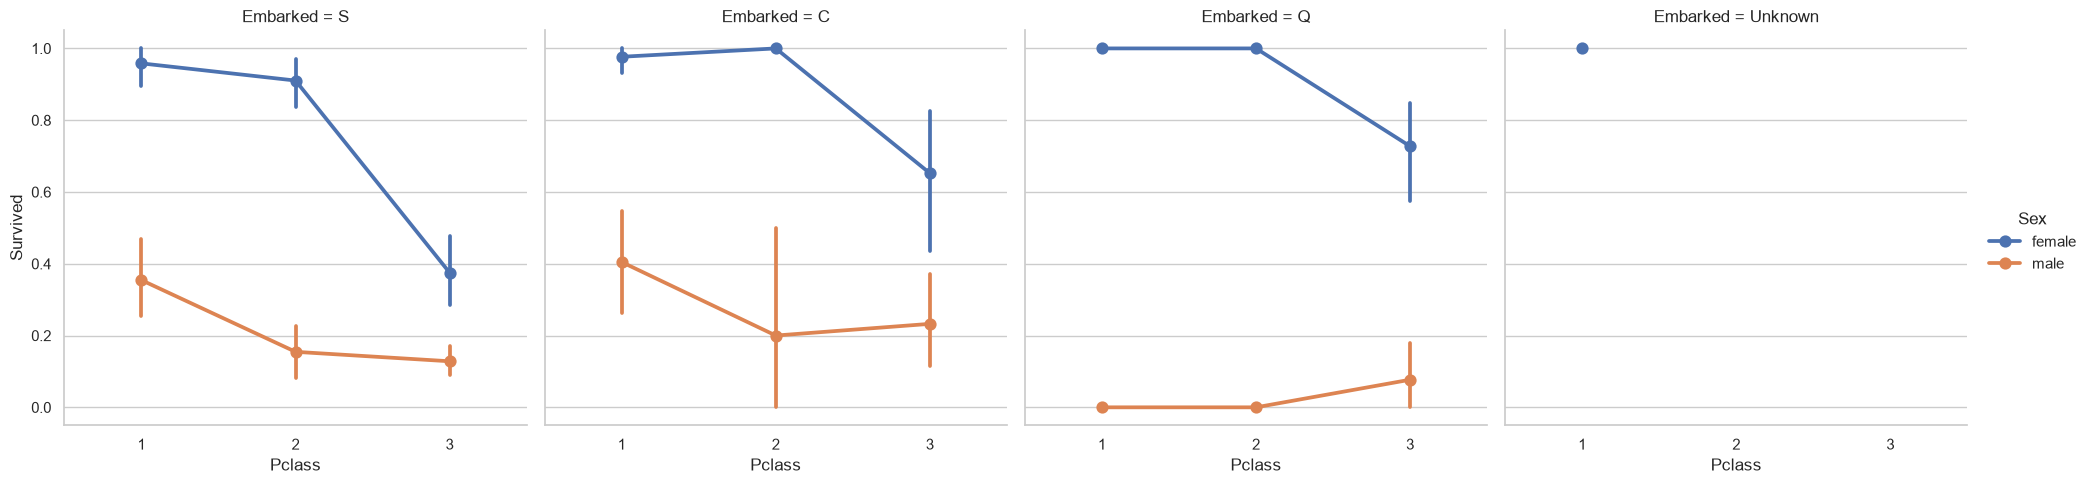

In [15]:
embarked_plot = df.assign(Embarked=df["Embarked"].fillna("Unknown"))

sns.catplot(data=embarked_plot, x="Pclass", y="Survived", hue="Sex", col="Embarked", kind="point")
plt.show()

## Embarkation

Embarkation port is kept as a categorical feature and missing values are imputed inside the pipeline

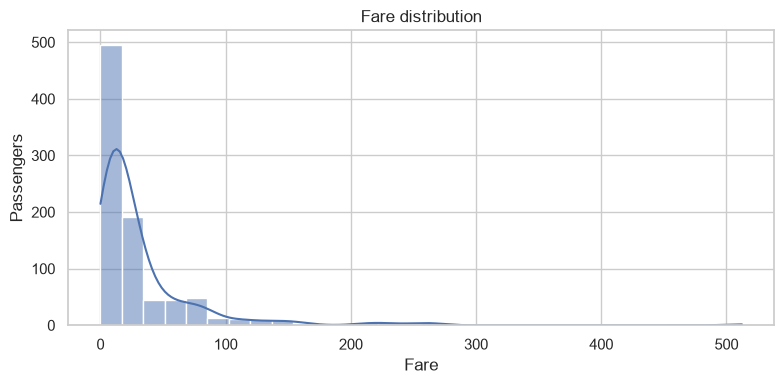

In [16]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Fare", bins=30, kde=True)

plt.xlabel("Fare")
plt.ylabel("Passengers")
plt.title("Fare distribution")
plt.tight_layout()
plt.show()

## Fare

Fare is strongly skewed, so the pipeline also creates log fare and fare per passenger

## Feature engineering

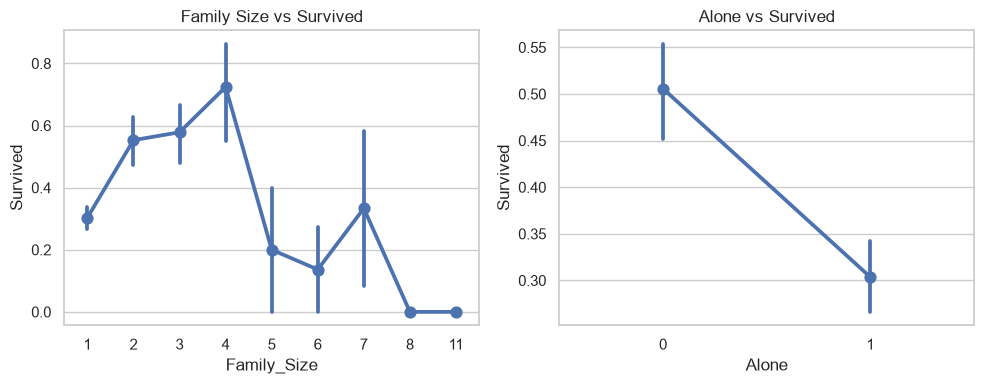

In [17]:
df["Family_Size"] = (df["Parch"] + df["SibSp"] + 1)
df["Alone"] = (df["Family_Size"] == 1).astype(int)

fig, axes = plt.subplots(1,2,figsize=(10, 4))

sns.pointplot(data=df,x="Family_Size",y="Survived",ax=axes[0])
axes[0].set_title("Family Size vs Survived")

sns.pointplot(data=df, x="Alone", y="Survived", ax=axes[1])
axes[1].set_title("Alone vs Survived")

plt.tight_layout()
plt.show()

In [18]:
df["Deck"] = df["Cabin"].str[0].fillna("U")
df["Ticket_Group_Size"] = df.groupby("Ticket")["Ticket"].transform("size")
df["Fare_Per_Person"] = df["Fare"] / df["Ticket_Group_Size"]
df["Name_Length"] = df["Name"].str.len()
df["Fare_Log"] = np.log1p(df["Fare"])

df[["Deck", "Ticket_Group_Size", "Fare_Per_Person", "Name_Length", "Fare_Log"]].head()

,Deck,Ticket_Group_Size,Fare_Per_Person,Name_Length,Fare_Log
0,U,1,7.2500,23,2.110213
1,C,1,71.2833,51,4.280593
2,U,1,7.9250,22,2.188856
3,C,2,26.5500,44,3.990834
4,U,1,8.0500,24,2.202765


## Engineered features

Families of two to four people had the highest survival rate at 58%. Large families survived less often than solo passengers: 16% versus 30%

- Title and deck are extracted from name and cabin
- Family size and travelling alone describe family structure
- Ticket and surname features describe travelling groups
- Group composition includes the number of women, children and average age
- Fare per passenger accounts for shared tickets
- Group statistics use no information from `Survived`

In [19]:
eda_features = ["Family_Size",
                "Alone",
                "Deck",
                "Ticket_Group_Size",
                "Fare_Per_Person",
                "Name_Length",
                "Fare_Log"]

df[eda_features].head()

,Family_Size,Alone,Deck,Ticket_Group_Size,Fare_Per_Person,Name_Length,Fare_Log
0,2,0,U,1,7.2500,23,2.110213
1,2,0,C,1,71.2833,51,4.280593
2,1,1,U,1,7.9250,22,2.188856
3,2,0,C,2,26.5500,44,3.990834
4,1,1,U,1,8.0500,24,2.202765


# Preprocessing pipeline

Feature engineering, imputation, scaling and encoding are combined in one pipeline

Group statistics are prepared from the available passenger manifest without using the target

In [20]:
numeric_features = NUMERIC_FEATURES
categorical_features = CATEGORICAL_FEATURES

feature_engineer = make_feature_engineer(raw_df.drop(columns="Survived"), test_df,)
preprocessor = make_preprocessor()


def make_model_pipeline(model):
    """Build an experimental pipeline with shared preprocessing"""
    return Pipeline([("features", clone(feature_engineer)),
                     ("preprocessor", clone(preprocessor)),
                     ("model", model)])

In [21]:
def prepare_native_catboost_features(X):
    """Build a pipeline with native CatBoost preprocessing"""
    data = X.copy()
    data[categorical_features] = (data[categorical_features].fillna("Unknown").astype(str))

    return data


native_catboost_transformer = FunctionTransformer(prepare_native_catboost_features, validate=False)

class NativeCatBoostClassifier(ClassifierMixin, BaseEstimator):
    """Sklearn-compatible wrapper for CatBoost with native categorical features"""
        
    def __init__(self, parameters=None, categorical_features=None):
        self.parameters = parameters
        self.categorical_features = categorical_features

    def fit(self, X, y):
        parameters = ({} if self.parameters is None else self.parameters)
        self.model_ = CatBoostClassifier(**parameters, loss_function="Logloss", random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1)
        self.model_.fit(X, y, cat_features=list(self.categorical_features))
        self.classes_ = np.unique(y)

        return self

    def predict(self, X):
        return self.model_.predict(X).astype(int).ravel()

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


def make_native_catboost(parameters):
    """Build the native CatBoost pipeline"""
    model = NativeCatBoostClassifier(parameters=parameters, categorical_features=tuple(categorical_features))

    return Pipeline([("features", clone(feature_engineer)),
                    ("native_preprocessor", clone(native_catboost_transformer)),
                    ("model", model)])

## Validation

A group-aware holdout keeps passengers with the same ticket together

Regular CV is used for exploratory models, while the main candidates are tuned with group-aware CV

Final candidates are compared using both regular and group-aware CV

The holdout is not used by the model selection code, but it was inspected during development and is not an untouched test set

In [22]:
X = raw_df.drop(columns="Survived")
Y = raw_df["Survived"]
groups = X["Ticket"]

train_index, test_index = next(group_cv.split(X, Y, groups))

train_X = X.iloc[train_index]
test_X = X.iloc[test_index]

train_Y = Y.iloc[train_index]
test_Y = Y.iloc[test_index]

train_groups = groups.iloc[train_index]

shared_tickets = set(train_X["Ticket"]) & set(test_X["Ticket"])

print("Train shape:", train_X.shape)
print("Test shape:", test_X.shape)
print("Train target ratio:", train_Y.mean().round(3))
print("Test target ratio:", test_Y.mean().round(3))
print("Shared tickets:", len(shared_tickets))

Train shape: (712, 11)
Test shape: (179, 11)
Train target ratio: 0.383
Test target ratio: 0.385
Shared tickets: 0


In [23]:
engineered_train = clone(feature_engineer).fit_transform(train_X, train_Y)
constant_features = [column for column in engineered_train.columns if engineered_train[column].nunique(dropna=False) <= 1]

pd.DataFrame({"Constant Feature": constant_features})

,Constant Feature


In [24]:
numeric_correlation = (engineered_train[numeric_features] .corr() .abs())
upper_correlation = numeric_correlation.where(np.triu(np.ones(numeric_correlation.shape), k=1).astype(bool))
high_correlation_pairs = (upper_correlation.stack().reset_index())
high_correlation_pairs.columns = ["Feature 1", "Feature 2", "Absolute Correlation"]
high_correlation_pairs = high_correlation_pairs[high_correlation_pairs["Absolute Correlation"] >= 0.8]
high_correlation_pairs.sort_values("Absolute Correlation", ascending=False).reset_index(drop=True)

,Feature 1,Feature 2,Absolute Correlation
0,Ticket_Child_Count,Surname_Child_Count,0.970641
1,Family_Size,Surname_Group_Size,0.963037
2,Ticket_Mean_Age,Surname_Mean_Age,0.951682
3,SibSp,Family_Size,0.898666
4,Age,Surname_Mean_Age,0.894346
5,SibSp,Surname_Group_Size,0.869203
6,Ticket_Female_Count,Surname_Female_Count,0.864960
7,Age,Ticket_Mean_Age,0.862811
8,Fare,Fare_Per_Person,0.826534
9,Ticket_Group_Size,Surname_Group_Size,0.807917


In [25]:
class SexRuleClassifier(ClassifierMixin, BaseEstimator):
    """Predict survival from passenger sex as a simple baseline"""
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        return self

    def predict(self, X):
        return (X["Sex"] == "female").astype(int).to_numpy()

    def predict_proba(self, X):
        predictions = self.predict(X)
        return np.column_stack([1 - predictions, predictions])

In [26]:
sex_pclass_tree = Pipeline([("preprocessor",ColumnTransformer([("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Sex", "Pclass"])])),
                            ("model",DecisionTreeClassifier(max_depth=2, random_state=SEED))])

models = {"Dummy Classifier": DummyClassifier(strategy="most_frequent"),
          "Sex Rule": SexRuleClassifier(),
          "Sex + Pclass Tree": sex_pclass_tree,
          "Logistic Regression": make_model_pipeline(LogisticRegression(max_iter=2000)),
          "Linear SVM": make_model_pipeline(SVC(kernel="linear")),
          "RBF SVM": make_model_pipeline(SVC(kernel="rbf")),
          "KNN": make_model_pipeline(KNeighborsClassifier()),
          "Decision Tree": make_model_pipeline(DecisionTreeClassifier(random_state=SEED)),
          "Random Forest": make_model_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=1))}

print("Models:", list(models))

Models: ['Dummy Classifier', 'Sex Rule', 'Sex + Pclass Tree', 'Logistic Regression', 'Linear SVM', 'RBF SVM', 'KNN', 'Decision Tree', 'Random Forest']


In [27]:
scoring = {"accuracy": "accuracy",
           "precision": make_scorer(precision_score, zero_division=0),
           "recall": make_scorer(recall_score, zero_division=0),
           "f1": make_scorer(f1_score, zero_division=0),
           "roc_auc": "roc_auc"}

In [28]:
cv_results = []
cv_accuracy_scores = {}

for model_name, model in models.items():
    scores = cross_validate(model, train_X, train_Y, cv=cv, scoring=scoring, n_jobs=-1)
    cv_accuracy_scores[model_name] = scores["test_accuracy"]

    cv_results.append({"Model": model_name,
                       "CV Accuracy Mean": scores["test_accuracy"].mean(),
                       "CV Accuracy Std": scores["test_accuracy"].std(),
                       "CV Precision": scores["test_precision"].mean(),
                       "CV Recall": scores["test_recall"].mean(),
                       "CV F1": scores["test_f1"].mean(),
                       "CV ROC AUC": scores["test_roc_auc"].mean()})

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values("CV Accuracy Mean", ascending=False).reset_index(drop=True)

cv_results_df.round(4)

,Model,CV Accuracy Mean,CV Accuracy Std,CV Precision,CV Recall,CV F1,CV ROC AUC
0,Logistic Regression,0.8258,0.0172,0.7883,0.7510,0.7674,0.8647
1,RBF SVM,0.8244,0.0266,0.7945,0.7364,0.7629,0.8493
2,Linear SVM,0.8216,0.0250,0.7948,0.7253,0.7566,0.8423
3,Random Forest,0.8216,0.0220,0.7833,0.7435,0.7616,0.8724
4,KNN,0.7851,0.0246,0.7457,0.6665,0.7033,0.8286
5,Sex Rule,0.7850,0.0309,0.7479,0.6666,0.7036,0.7627
6,Sex + Pclass Tree,0.7780,0.0243,0.7849,0.6084,0.6763,0.8171
7,Decision Tree,0.7499,0.0264,0.6812,0.6630,0.6701,0.7328
8,Dummy Classifier,0.6166,0.0027,0.0000,0.0000,0.0000,0.5000


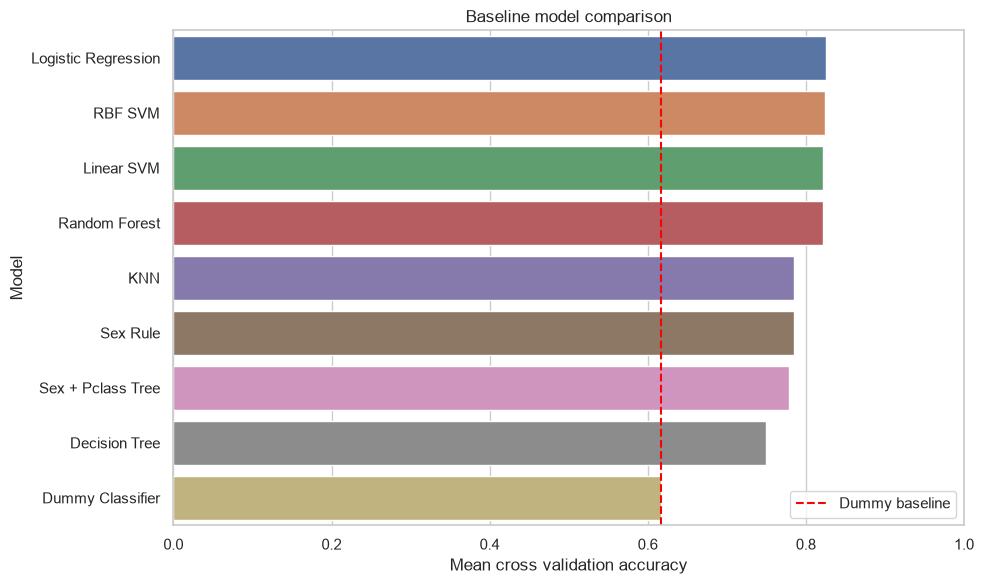

In [29]:
plt.figure(figsize=(10, 6))
sns.barplot(data=cv_results_df, x="CV Accuracy Mean", y="Model", hue="Model", legend=False)
plt.axvline(x=cv_results_df.loc[cv_results_df["Model"] == "Dummy Classifier", "CV Accuracy Mean"].iloc[0], color="red", linestyle="--", label="Dummy baseline")

plt.xlabel("Mean cross validation accuracy")
plt.ylabel("Model")
plt.title("Baseline model comparison")
plt.xlim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

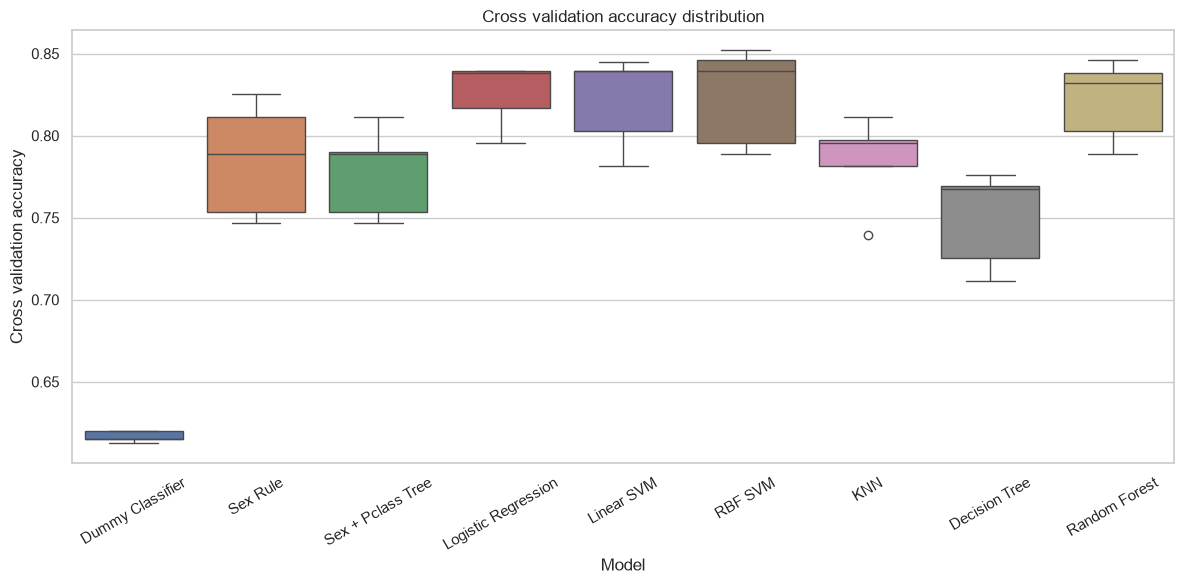

In [30]:
cv_accuracy_df = pd.DataFrame(cv_accuracy_scores)

plt.figure(figsize=(12, 6))

sns.boxplot(data=cv_accuracy_df)

plt.xlabel("Model")
plt.ylabel("Cross validation accuracy")
plt.title("Cross validation accuracy distribution")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Hyperparameter optimization

The main tree models are tuned with group-aware CV to reduce overfitting to shared tickets

In [31]:
def evaluate_pipeline_trial(trial, pipeline, grouped=False):
    """Evaluate a pipeline with regular or group-aware CV"""
    if grouped:
        scores = cross_val_score(pipeline, train_X, train_Y, cv=group_cv, groups=train_groups, scoring="accuracy", n_jobs=-1)
    else:
        scores = cross_val_score(pipeline, train_X, train_Y, cv=cv, scoring="accuracy", n_jobs=-1)

    trial.set_user_attr("CV Accuracy Std", float(scores.std()))

    return float(scores.mean())


def evaluate_trial(trial, model, grouped=False):
    """Build and evaluate a model pipeline for one Optuna trial"""
    pipeline = make_model_pipeline(model)

    return evaluate_pipeline_trial(trial, pipeline, grouped)


def run_study(name, objective, start=None, n_trials=40):
    """Run an Optuna hyperparameter study"""
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=name)

    if start is not None:
        study.enqueue_trial(start)

    study.optimize(objective, n_trials=n_trials)

    print(name, "CV accuracy:", round(study.best_value, 4))
    print("CV standard deviation:", round(study.best_trial.user_attrs["CV Accuracy Std"], 4))
    print("Best parameters:", study.best_params)

    return study

In [32]:
def suggest_catboost_parameters(trial):
    return {"iterations": trial.suggest_int("iterations", 200, 800, step=100),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            "depth": trial.suggest_int("depth", 3, 6),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 20, log=True),
            "random_strength": trial.suggest_float("random_strength", 0.1, 5, log=True),
            "border_count": trial.suggest_categorical( "border_count", [32, 64, 128])}


def catboost_objective(trial):
    parameters = suggest_catboost_parameters(trial)
    model = CatBoostClassifier(**parameters, loss_function="Logloss", random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1)

    return evaluate_trial(trial, model, grouped=True)


catboost_start = {"iterations": 500,
                  "learning_rate": 0.03,
                  "depth": 5,
                  "l2_leaf_reg": 5.0,
                  "random_strength": 1.0,
                  "border_count": 64}

catboost_study = run_study("CatBoost One-Hot Group CV", catboost_objective, catboost_start)

best_optuna_catboost = make_model_pipeline(CatBoostClassifier(**catboost_study.best_params, loss_function="Logloss", random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1))

CatBoost One-Hot Group CV CV accuracy: 0.8315
CV standard deviation: 0.0254
Best parameters: {'iterations': 200, 'learning_rate': 0.04299542921255021, 'depth': 3, 'l2_leaf_reg': 14.407964235716207, 'random_strength': 0.894679420410602, 'border_count': 32}


In [33]:
def native_catboost_objective(trial):
    parameters = suggest_catboost_parameters(trial)
    pipeline = make_native_catboost(parameters)

    return evaluate_pipeline_trial(trial, pipeline, grouped=True)


native_catboost_study = run_study("CatBoost Native Group CV", native_catboost_objective, catboost_start)
best_optuna_native_catboost = make_native_catboost(native_catboost_study.best_params)

CatBoost Native Group CV CV accuracy: 0.8231
CV standard deviation: 0.0228
Best parameters: {'iterations': 300, 'learning_rate': 0.027823246459370333, 'depth': 3, 'l2_leaf_reg': 11.259992651913315, 'random_strength': 0.5876631575327015, 'border_count': 32}


In [34]:
def gradient_boosting_objective(trial):
    parameters = {"n_estimators": trial.suggest_int("n_estimators", 50, 400, step=25),
                  "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
                  "max_depth": trial.suggest_int("max_depth", 2, 4),
                  "min_samples_split": trial.suggest_int("min_samples_split", 5, 30),
                  "min_samples_leaf": trial.suggest_int("min_samples_leaf", 3, 15),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0, step=0.1),
                  "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2"])}

    model = GradientBoostingClassifier(**parameters, random_state=SEED)

    return evaluate_trial(trial, model, grouped=True)


gradient_boosting_start = {"n_estimators": 100,
                           "learning_rate": 0.05,
                           "max_depth": 3,
                           "min_samples_split": 10,
                           "min_samples_leaf": 5,
                           "subsample": 0.8,
                           "max_features": None}

gradient_boosting_study = run_study("Gradient Boosting Group CV", gradient_boosting_objective, gradient_boosting_start)
best_optuna_gradient_boosting = make_model_pipeline(GradientBoostingClassifier(**gradient_boosting_study.best_params, random_state=SEED))

Gradient Boosting Group CV CV accuracy: 0.8189
CV standard deviation: 0.0274
Best parameters: {'n_estimators': 300, 'learning_rate': 0.010308507081845263, 'max_depth': 3, 'min_samples_split': 30, 'min_samples_leaf': 9, 'subsample': 0.6, 'max_features': 'log2'}


In [35]:
def random_forest_objective(trial):
    parameters = {"n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
                  "max_depth": trial.suggest_categorical("max_depth", [4, 6, 8, 10, 12]),
                  "min_samples_split": trial.suggest_int("min_samples_split", 5, 30),
                  "min_samples_leaf": trial.suggest_int("min_samples_leaf", 3, 15),
                  "max_features": trial.suggest_categorical("max_features",["sqrt", "log2", 0.5, 0.8]),
                  "criterion": trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"]),
                  "class_weight": trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"]),
                  "max_samples": trial.suggest_float( "max_samples", 0.6, 1.0, step=0.1)}

    model = RandomForestClassifier(**parameters, bootstrap=True, random_state=SEED, n_jobs=1)

    return evaluate_trial(trial, model, grouped=True)


random_forest_start = {"n_estimators": 200,
                       "max_depth": 8,
                       "min_samples_split": 10,
                       "min_samples_leaf": 5,
                       "max_features": "sqrt",
                       "criterion": "gini",
                       "class_weight": None,
                       "max_samples": 0.8}

random_forest_study = run_study("Random Forest Group CV", random_forest_objective, random_forest_start)
best_optuna_random_forest = make_model_pipeline(RandomForestClassifier(**random_forest_study.best_params, bootstrap=True, random_state=SEED, n_jobs=1))

Random Forest Group CV CV accuracy: 0.8105
CV standard deviation: 0.0267
Best parameters: {'n_estimators': 550, 'max_depth': 8, 'min_samples_split': 12, 'min_samples_leaf': 7, 'max_features': 'sqrt', 'criterion': 'gini', 'class_weight': 'balanced', 'max_samples': 0.9}


In [36]:
def xgboost_objective(trial):
    parameters = {"n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
                  "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                  "max_depth": trial.suggest_int("max_depth", 2, 8),
                  "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0, step=0.1),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0, step=0.1),
                  "gamma": trial.suggest_float("gamma", 0, 5),
                  "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
                  "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10, log=True)}

    model = xgb.XGBClassifier(**parameters, objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=1, verbosity=0)

    return evaluate_trial(trial, model)

xgboost_start = {"n_estimators": 400,
                 "learning_rate": 0.1,
                 "max_depth": 3,
                 "min_child_weight": 1,
                 "subsample": 1.0,
                 "colsample_bytree": 1.0,
                 "gamma": 0.0,
                 "reg_alpha": 0.0,
                 "reg_lambda": 1.0}

xgboost_study = run_study("XGBoost", xgboost_objective, xgboost_start)
best_optuna_xgboost = make_model_pipeline(xgb.XGBClassifier(**xgboost_study.best_params, objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=1, verbosity=0))

XGBoost CV accuracy: 0.8342
CV standard deviation: 0.0232
Best parameters: {'n_estimators': 150, 'learning_rate': 0.17096379318276655, 'max_depth': 2, 'min_child_weight': 2, 'subsample': 1.0, 'colsample_bytree': 1.0, 'gamma': 1.5417490261500335, 'reg_alpha': 0.3802193431205469, 'reg_lambda': 0.21736763415670315}


In [37]:
def lightgbm_objective(trial):
    parameters = {"n_estimators": trial.suggest_int("n_estimators", 50, 800, step=50),
                  "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                  "max_depth": trial.suggest_categorical("max_depth", [3, 4, 5, 6, -1]),
                  "num_leaves": trial.suggest_categorical("num_leaves", [7, 15, 31, 63]),
                  "min_child_samples": trial.suggest_int("min_child_samples", 5, 50, step=5),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0, step=0.1),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0, step=0.1),
                  "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
                  "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10, log=True)}

    model = LGBMClassifier(**parameters, objective="binary", subsample_freq=1, random_state=SEED, n_jobs=1, verbosity=-1, force_col_wise=True)

    return evaluate_trial(trial, model, grouped=True)

lightgbm_start = {"n_estimators": 100,
                  "learning_rate": 0.1,
                  "max_depth": 4,
                  "num_leaves": 7,
                  "min_child_samples": 20,
                  "subsample": 1.0,
                  "colsample_bytree": 1.0,
                  "reg_alpha": 0.0,
                  "reg_lambda": 1.0}

lightgbm_study = run_study("LightGBM Group CV", lightgbm_objective, lightgbm_start)
best_optuna_lightgbm = make_model_pipeline(LGBMClassifier(**lightgbm_study.best_params, objective="binary", subsample_freq=1, random_state=SEED, n_jobs=1, verbosity=-1, force_col_wise=True))

LightGBM Group CV CV accuracy: 0.8146
CV standard deviation: 0.0209
Best parameters: {'n_estimators': 350, 'learning_rate': 0.031061165492543123, 'max_depth': 5, 'num_leaves': 31, 'min_child_samples': 30, 'subsample': 0.7, 'colsample_bytree': 0.8, 'reg_alpha': 3.254554161495312, 'reg_lambda': 0.2907950920404268}


In [38]:
def svc_objective(trial):
    parameters = {"C": trial.suggest_float("C", 0.01, 100, log=True),
                  "gamma": trial.suggest_categorical("gamma", ["scale", "auto", 0.001, 0.01, 0.1, 0.5, 1.0]),
                  "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}

    model = SVC(kernel="rbf", **parameters)

    return evaluate_trial(trial, model, grouped=True)

svc_start = {"C": 2.0,
             "gamma": "scale",
             "class_weight": None}

svc_study = run_study("SVC Group CV", svc_objective, svc_start)
best_optuna_svc = make_model_pipeline(SVC(**svc_study.best_params, kernel="rbf", random_state=SEED))
calibrated_svc = CalibratedClassifierCV(estimator=clone(best_optuna_svc), method="sigmoid", cv=cv, ensemble=False)

SVC Group CV CV accuracy: 0.8174
CV standard deviation: 0.0416
Best parameters: {'C': 1.854345907263523, 'gamma': 0.01, 'class_weight': 'balanced'}


In [39]:
def logistic_objective(trial):
    parameters = {"C": trial.suggest_float("C", 0.001, 100, log=True),
                  "l1_ratio": trial.suggest_float("l1_ratio", 0, 1, step=0.05),
                  "class_weight": trial.suggest_categorical( "class_weight", [None, "balanced"])}

    model = LogisticRegression(**parameters, solver="saga", max_iter=5000, random_state=SEED)

    return evaluate_trial(trial, model)

logistic_start = {"C": 0.1,
                  "l1_ratio": 1.0,
                  "class_weight": None}

logistic_study = run_study("Logistic Regression", logistic_objective, logistic_start)
best_optuna_logistic = make_model_pipeline(LogisticRegression(**logistic_study.best_params, solver="saga", max_iter=5000, random_state=SEED))

Logistic Regression CV accuracy: 0.8258
CV standard deviation: 0.0172
Best parameters: {'C': 0.9163741808778786, 'l1_ratio': 0.0, 'class_weight': None}


In [40]:
def knn_objective(trial):
    parameters = {"n_neighbors": trial.suggest_int("n_neighbors", 3, 51, step=2),
                  "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
                  "p": trial.suggest_int("p", 1, 2),
                  "leaf_size": trial.suggest_int("leaf_size", 10, 60, step=5),
                  "algorithm": trial.suggest_categorical("algorithm", ["auto", "ball_tree", "kd_tree", "brute"])}

    model = KNeighborsClassifier(**parameters, n_jobs=1)

    return evaluate_trial(trial, model)

knn_start = {"n_neighbors": 7,
             "weights": "distance",
             "p": 1,
             "leaf_size": 30,
             "algorithm": "auto"}

knn_study = run_study("KNN", knn_objective, knn_start)
best_optuna_knn = make_model_pipeline(KNeighborsClassifier(**knn_study.best_params, n_jobs=1))

KNN CV accuracy: 0.8272
CV standard deviation: 0.0154
Best parameters: {'n_neighbors': 25, 'weights': 'distance', 'p': 1, 'leaf_size': 35, 'algorithm': 'auto'}


In [41]:
def decision_tree_objective(trial):
    parameters = {"criterion": trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"]),
                  "splitter": trial.suggest_categorical("splitter", ["best", "random"]),
                  "max_depth": trial.suggest_categorical("max_depth", [None, 3, 4, 5, 6, 8, 10, 12]),
                  "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
                  "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 15),
                  "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2", 0.5, 0.8]),
                  "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}

    model = DecisionTreeClassifier(**parameters, random_state=SEED)

    return evaluate_trial(trial, model)

decision_tree_start = {"criterion": "entropy",
                       "splitter": "best",
                       "max_depth": 6,
                       "min_samples_split": 2,
                       "min_samples_leaf": 5,
                       "max_features": None,
                       "class_weight": None}

decision_tree_study = run_study("Decision Tree", decision_tree_objective, decision_tree_start)
best_optuna_decision_tree = make_model_pipeline(DecisionTreeClassifier(**decision_tree_study.best_params, random_state=SEED))

Decision Tree CV accuracy: 0.8174
CV standard deviation: 0.0298
Best parameters: {'criterion': 'entropy', 'splitter': 'best', 'max_depth': 6, 'min_samples_split': 15, 'min_samples_leaf': 9, 'max_features': 0.5, 'class_weight': None}


In [42]:
def bagging_tree_objective(trial):
    parameters = {"base_criterion": trial.suggest_categorical( "base_criterion", ["gini", "entropy", "log_loss"]),
                  "base_max_depth": trial.suggest_categorical( "base_max_depth", [3, 4, 5, 6, 8, 10]),
                  "base_min_samples_split": trial.suggest_int( "base_min_samples_split", 5, 30),
                  "base_min_samples_leaf": trial.suggest_int( "base_min_samples_leaf", 3, 15),
                  "n_estimators": trial.suggest_int( "n_estimators", 50, 300, step=50),
                  "max_samples": trial.suggest_float( "max_samples", 0.6, 1.0, step=0.1),
                  "max_features": trial.suggest_float("max_features", 0.6, 1.0, step=0.1)}

    base_tree = DecisionTreeClassifier(criterion=parameters["base_criterion"],
                                       max_depth=parameters["base_max_depth"],
                                       min_samples_split=parameters["base_min_samples_split"],
                                       min_samples_leaf=parameters["base_min_samples_leaf"],
                                       random_state=SEED)

    model = BaggingClassifier(estimator=base_tree,
                              n_estimators=parameters["n_estimators"],
                              max_samples=parameters["max_samples"],
                              max_features=parameters["max_features"],
                              bootstrap=True,
                              random_state=SEED,
                              n_jobs=1)

    return evaluate_trial(trial, model, grouped=True)


bagging_tree_start = {"base_criterion": "entropy",
                      "base_max_depth": 6,
                      "base_min_samples_split": 10,
                      "base_min_samples_leaf": 5,
                      "n_estimators": 150,
                      "max_samples": 0.8,
                      "max_features": 0.8}

bagging_tree_study = run_study("Bagging Decision Tree Group CV", bagging_tree_objective, bagging_tree_start)

bagging_tree_parameters = bagging_tree_study.best_params

best_bagging_tree_base = DecisionTreeClassifier(criterion=bagging_tree_parameters["base_criterion"],
                                                max_depth=bagging_tree_parameters["base_max_depth"],
                                                min_samples_split=bagging_tree_parameters["base_min_samples_split"],
                                                min_samples_leaf=bagging_tree_parameters["base_min_samples_leaf"],
                                                random_state=SEED)

best_optuna_bagging_tree = make_model_pipeline(BaggingClassifier(estimator=best_bagging_tree_base,
                                                                 n_estimators=bagging_tree_parameters["n_estimators"],
                                                                 max_samples=bagging_tree_parameters["max_samples"],
                                                                 max_features=bagging_tree_parameters["max_features"],
                                                                 bootstrap=True,
                                                                 random_state=SEED,
                                                                 n_jobs=1))

Bagging Decision Tree Group CV CV accuracy: 0.8174
CV standard deviation: 0.0317
Best parameters: {'base_criterion': 'entropy', 'base_max_depth': 8, 'base_min_samples_split': 22, 'base_min_samples_leaf': 3, 'n_estimators': 100, 'max_samples': 1.0, 'max_features': 0.6}


## PyTorch DNN

A two-layer DNN is tuned with regular stratified CV and fold-specific preprocessing

It uses BCEWithLogitsLoss. Alternative losses and early stopping were not tested

In [43]:
def dnn_objective(trial):
    parameters = {
        "hidden_size_1": trial.suggest_categorical("hidden_size_1", [8, 16, 32, 64]),
        "hidden_size_2": trial.suggest_categorical("hidden_size_2", [4, 8, 16, 32]),
        "dropout_1": trial.suggest_float("dropout_1", 0.1, 0.5, step=0.05),
        "dropout_2": trial.suggest_float("dropout_2", 0, 0.4, step=0.05),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32, 64]),
        "epochs": trial.suggest_int("epochs", 30, 120, step=15),
        "activation": trial.suggest_categorical("activation", ["ReLU", "LeakyReLU", "ELU"]),
        "batch_norm": trial.suggest_categorical("batch_norm", [True, False]),
        "optimizer": trial.suggest_categorical("optimizer", ["Adam", "AdamW"]),
        "scheduler": trial.suggest_categorical("scheduler", ["None", "Cosine"])}

    fold_accuracies = []

    for fold_number, indexes in enumerate(cv.split(train_X, train_Y)):
        fold_train_index, fold_val_index = indexes
        fold_seed = SEED + fold_number

        fold_train_X = train_X.iloc[fold_train_index]
        fold_val_X = train_X.iloc[fold_val_index]
        fold_train_Y = train_Y.iloc[fold_train_index]
        fold_val_Y = train_Y.iloc[fold_val_index]

        fold_transformer = Pipeline([("features", clone(feature_engineer)),
                                     ("preprocessor", clone(preprocessor))])

        train_data = fold_transformer.fit_transform(fold_train_X, fold_train_Y)
        val_data = fold_transformer.transform(fold_val_X)

        model = train_dnn(parameters, train_data, fold_train_Y, fold_seed)

        val_features = torch.tensor(val_data, dtype=torch.float32)

        with torch.no_grad():
            logits = model(val_features)
            predictions = (logits.numpy().ravel() >= 0).astype(int)

        accuracy = accuracy_score(fold_val_Y, predictions)
        fold_accuracies.append(accuracy)

        trial.report(np.mean(fold_accuracies), step=fold_number)

        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("CV Accuracy Std", float(np.std(fold_accuracies)))

    return float(np.mean(fold_accuracies))

In [44]:
dnn_sampler = optuna.samplers.TPESampler(seed=SEED)
dnn_pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2)
dnn_study = optuna.create_study(direction="maximize", sampler=dnn_sampler, pruner=dnn_pruner, study_name="pytorch_dnn")
dnn_study.enqueue_trial({"hidden_size_1": 16,
                         "hidden_size_2": 8,
                         "dropout_1": 0.35,
                         "dropout_2": 0,
                         "learning_rate": 0.0005,
                         "weight_decay": 0.005,
                         "batch_size": 32,
                         "activation": "ReLU",
                         "batch_norm": True,
                         "optimizer": "AdamW",
                         "scheduler": "Cosine",
                         "epochs": 60})

dnn_study.optimize(dnn_objective, n_trials=30)

print("DNN Optuna CV accuracy:", round(dnn_study.best_value, 4))
print("DNN CV standard deviation:", round(dnn_study.best_trial.user_attrs["CV Accuracy Std"], 4))
print("Best DNN parameters:")
print(dnn_study.best_params)
print("CatBoost Optuna CV accuracy:", round(catboost_study.best_value, 4))

DNN Optuna CV accuracy: 0.83
DNN CV standard deviation: 0.025
Best DNN parameters:
{'hidden_size_1': 16, 'hidden_size_2': 4, 'dropout_1': 0.2, 'dropout_2': 0.0, 'learning_rate': 0.00019986730447841636, 'weight_decay': 7.527339029445822e-05, 'batch_size': 16, 'epochs': 90, 'activation': 'ELU', 'batch_norm': False, 'optimizer': 'Adam', 'scheduler': 'None'}
CatBoost Optuna CV accuracy: 0.8315


In [45]:
base_voting_estimators = [("catboost", best_optuna_catboost),
                          ("gradient_boosting", best_optuna_gradient_boosting),
                          ("lightgbm", best_optuna_lightgbm),
                          ("bagging_tree", best_optuna_bagging_tree)]

hard_voting_estimators = (base_voting_estimators + [("svc", best_optuna_svc)])
soft_voting_estimators = (base_voting_estimators + [("svc", calibrated_svc)])
best_optuna_hard_voting = VotingClassifier(estimators=hard_voting_estimators, voting="hard", n_jobs=1)
hard_voting_optuna_scores = cross_val_score(best_optuna_hard_voting, train_X, train_Y, cv=cv, scoring="accuracy", n_jobs=-1)

print("Equal Hard Voting:", round(hard_voting_optuna_scores.mean(), 4))
print("CV standard deviation:", round(hard_voting_optuna_scores.std(), 4))

Equal Hard Voting: 0.8314
CV standard deviation: 0.0267


In [46]:
best_optuna_soft_voting = VotingClassifier(estimators=soft_voting_estimators, voting="soft", n_jobs=1)
soft_voting_optuna_scores = cross_val_score(best_optuna_soft_voting, train_X, train_Y, cv=cv, scoring="accuracy", n_jobs=-1)

print("Equal Soft Voting:", round(soft_voting_optuna_scores.mean(), 4))
print("CV standard deviation:", round(soft_voting_optuna_scores.std(), 4))

Equal Soft Voting: 0.8328
CV standard deviation: 0.0223


## Voting ensembles

Hard and soft voting use equal weights

Their base models were tuned with group-aware CV and are evaluated again in the final comparison

In [47]:
stacking_logistic_model = StackingClassifier(estimators=soft_voting_estimators, final_estimator=LogisticRegression(max_iter=2000, random_state=SEED), cv=cv, stack_method="predict_proba", passthrough=False, n_jobs=1)
stacking_logistic_scores = cross_val_score(stacking_logistic_model, train_X, train_Y, cv=cv, scoring="accuracy", n_jobs=-1)

print("Stacking Logistic:", round(stacking_logistic_scores.mean(), 4))
print("CV standard deviation:", round(stacking_logistic_scores.std(), 4))

Stacking Logistic: 0.8272
CV standard deviation: 0.0262


In [48]:
stacking_ridge_model = StackingClassifier(estimators=soft_voting_estimators, final_estimator=RidgeClassifier(alpha=1.0), cv=cv, stack_method="predict_proba", passthrough=False, n_jobs=1)
stacking_ridge_scores = cross_val_score(stacking_ridge_model, train_X, train_Y, cv=cv, scoring="accuracy", n_jobs=-1)

print("Stacking Ridge:", round(stacking_ridge_scores.mean(), 4))
print("CV standard deviation:", round(stacking_ridge_scores.std(), 4))

Stacking Ridge: 0.823
CV standard deviation: 0.0271


## Final model comparison

All model families are evaluated with the same repeated stratified and group-aware cross-validation

The selection score is the mean of both estimates

In [49]:
best_optuna_dnn = make_model_pipeline(
    TorchDNNClassifier(parameters=dnn_study.best_params, random_state=SEED))

final_candidates = {"Dummy Classifier": models["Dummy Classifier"],
                    "Sex Rule": models["Sex Rule"],
                    "Sex + Pclass Tree": models["Sex + Pclass Tree"],
                    "Logistic Regression": best_optuna_logistic,
                    "KNN": best_optuna_knn,
                    "SVC": best_optuna_svc,
                    "Decision Tree": best_optuna_decision_tree,
                    "Random Forest": best_optuna_random_forest,
                    "Gradient Boosting": best_optuna_gradient_boosting,
                    "XGBoost": best_optuna_xgboost,
                    "LightGBM": best_optuna_lightgbm,
                    "CatBoost One-Hot": best_optuna_catboost,
                    "CatBoost Native": best_optuna_native_catboost,
                    "Bagging Decision Tree": best_optuna_bagging_tree,
                    "PyTorch DNN": best_optuna_dnn,
                    "Equal Hard Voting": best_optuna_hard_voting,
                    "Equal Soft Voting": best_optuna_soft_voting,
                    "Stacking Logistic": stacking_logistic_model,
                    "Stacking Ridge": stacking_ridge_model,}

baseline_names = {"Dummy Classifier", "Sex Rule", "Sex + Pclass Tree",}
ensemble_names = {"Equal Hard Voting", "Equal Soft Voting", "Stacking Logistic", "Stacking Ridge"}
comparison_results = []

for name, model in final_candidates.items():
    if name in baseline_names:
        model_type = "Baseline"
    elif name in ensemble_names:
        model_type = "Ensemble"
    else:
        model_type = "Single model"

    n_jobs = 1 if name == "PyTorch DNN" else -1
    metrics = evaluate_model(model, X, Y, groups, n_jobs=n_jobs,)

    comparison_results.append({"Model": name, "Type": model_type, **metrics, "CV Gap": metrics["Regular CV"] - metrics["Group CV"],})

comparison_results_df = pd.DataFrame(comparison_results)
comparison_results_df = comparison_results_df.sort_values("Selection Score", ascending=False,).reset_index(drop=True)

selected_model_name = comparison_results_df.loc[0, "Model"]

print("Selected model:", selected_model_name)
comparison_results_df.round(4)

Selected model: CatBoost One-Hot


,Model,Type,Regular CV,Group CV,Selection Score,Holdout Accuracy,CV Gap
0,CatBoost One-Hot,Single model,0.8291,0.8259,0.8275,0.8492,0.0032
1,Equal Soft Voting,Ensemble,0.8319,0.8216,0.8268,0.8436,0.0103
2,Equal Hard Voting,Ensemble,0.8286,0.8212,0.8249,0.8436,0.0075
3,CatBoost Native,Single model,0.8226,0.8226,0.8226,0.8380,-0.0000
4,Stacking Logistic,Ensemble,0.8263,0.8188,0.8226,0.8492,0.0075
5,Gradient Boosting,Single model,0.8258,0.8160,0.8209,0.8492,0.0098
6,Stacking Ridge,Ensemble,0.8230,0.8174,0.8202,0.8492,0.0056
7,SVC,Single model,0.8202,0.8188,0.8195,0.8324,0.0014
8,Logistic Regression,Single model,0.8221,0.8141,0.8181,0.8212,0.0080
9,PyTorch DNN,Single model,0.8226,0.8104,0.8165,0.8492,0.0122


## Checking group features

The same CatBoost model is evaluated with and without group composition features

In [50]:
group_composition_features = ["Ticket_Female_Count", "Ticket_Child_Count", "Ticket_Mean_Age", "Surname_Female_Count", "Surname_Child_Count", "Surname_Mean_Age"]

reduced_numeric_features = [feature for feature in numeric_features if feature not in group_composition_features]
reduced_preprocessor = make_preprocessor(numeric_features=reduced_numeric_features, categorical_features=categorical_features)

catboost_without_group_features = Pipeline([("features", clone(feature_engineer)),
                                            ("preprocessor", reduced_preprocessor),
                                            ("model", clone(best_optuna_catboost.named_steps["model"]))])

ablation_models = {"Without group composition": catboost_without_group_features,
                   "With group composition": best_optuna_catboost}

ablation_results = []

for name, model in ablation_models.items():
    regular_scores = cross_val_score(model,train_X, train_Y, cv=regular_cv, scoring="accuracy", n_jobs=-1)
    group_scores = cross_val_score(model, train_X, train_Y, cv=group_cv, groups=train_groups, scoring="accuracy", n_jobs=-1)
    ablation_results.append({"Feature Set": name,
                             "Regular CV": regular_scores.mean(),
                             "Group CV": group_scores.mean()})

ablation_results_df = pd.DataFrame(ablation_results)

ablation_results_df.round(4)

,Feature Set,Regular CV,Group CV
0,Without group composition,0.8235,0.8245
1,With group composition,0.8291,0.8315


Group composition slightly improved both validation estimates, so the features were kept

,Model,Accuracy,Precision,Recall,F1
0,CatBoost One-Hot,0.8492,0.8088,0.7971,0.8029
1,Sex Rule,0.7933,0.7286,0.7391,0.7338


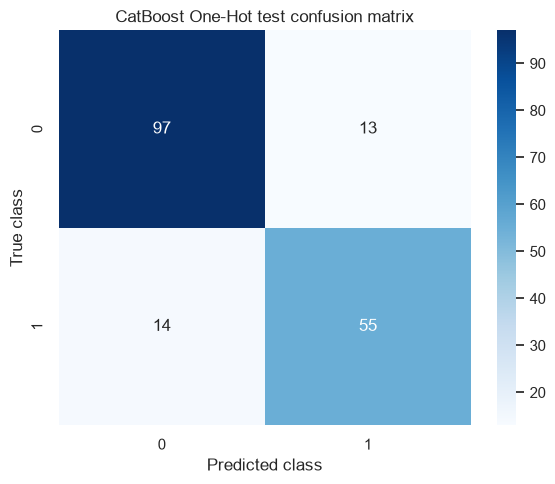

In [51]:
def compute_metrics(model_name, y_true, y_pred):
    """Calculate the main binary classification metrics"""
    return {"Model": model_name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}


final_model_name = selected_model_name
final_model = clone(final_candidates[selected_model_name])
final_model.fit(train_X, train_Y)
test_predictions = final_model.predict(test_X)

baseline_model_name = "Sex Rule"
baseline_model = SexRuleClassifier()
baseline_model.fit(train_X, train_Y)

baseline_predictions = baseline_model.predict(test_X)

final_test_results = pd.DataFrame([compute_metrics(final_model_name, test_Y, test_predictions),
                                   compute_metrics(baseline_model_name, test_Y, baseline_predictions)])

display(final_test_results.round(4))
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(test_Y, test_predictions), annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title(f"{final_model_name} test confusion matrix")
plt.tight_layout()
plt.show()

## Final holdout evaluation

The selected model is compared with the Sex Rule baseline on the group-aware holdout

# Kaggle submissions

The model selected by local validation is fitted on all labelled passengers and exported as the main submission

The public leaderboard is used only as an external check, not for model selection

An optional five-fold submission averages predicted probabilities before applying the classification threshold

In [52]:
submission_dir = Path("submissions/full_fit")
submission_dir.mkdir(parents=True, exist_ok=True)

production_model = clone(final_candidates[selected_model_name])
production_model.fit(X, Y)

full_fit_predictions = production_model.predict(test_df).astype(int)

selected_slug = (selected_model_name.lower() .replace(" ", "_") .replace("-", "_") .replace("+", "plus"))
full_fit_filename = submission_dir / f"titanic_{selected_slug}_full_fit.csv"

full_fit_submission = pd.DataFrame({"PassengerId": test_df["PassengerId"],
                                    "Survived": full_fit_predictions,})

full_fit_submission.to_csv(full_fit_filename, index=False)

print("Production model:", selected_model_name)
print("Predicted survivors:", full_fit_predictions.sum())
print("Saved:", full_fit_filename)

full_fit_submission.head()

Production model: CatBoost One-Hot
Predicted survivors: 162
Saved: submissions\full_fit\titanic_catboost_one_hot_full_fit.csv


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [53]:
five_fold_dir = Path("submissions/cv")
five_fold_dir.mkdir(parents=True, exist_ok=True)

fold_probabilities = []

for train_index, _ in cv.split(X, Y):
    fold_model = clone(final_candidates[selected_model_name])
    fold_model.fit(X.iloc[train_index], Y.iloc[train_index])

    probabilities = fold_model.predict_proba(test_df)[:, 1]
    fold_probabilities.append(probabilities)

mean_probabilities = np.mean(fold_probabilities, axis=0)
five_fold_predictions = (mean_probabilities >= 0.5).astype(int)

selected_slug = selected_model_name.lower().replace(" ", "_").replace("-", "_").replace("+", "plus")
five_fold_filename = five_fold_dir / f"titanic_{selected_slug}_5fold.csv"

five_fold_submission = pd.DataFrame({"PassengerId": test_df["PassengerId"],
                                     "Survived": five_fold_predictions})

five_fold_submission.to_csv(five_fold_filename, index=False)
different_predictions = (full_fit_predictions != five_fold_predictions).sum()

print("Saved:", five_fold_filename)
print("Different predictions:", different_predictions)

five_fold_submission.head()

Saved: submissions\cv\titanic_catboost_one_hot_5fold.csv
Different predictions: 2


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
